# HighFold3 环肽预测

## 输入准备、模型调用与 TAS2R14 复合物

从环肽与蛋白链输入出发，调用 HighFold3，展示预测结构、置信度与 CLB 位点改造。


In [1]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
from io import StringIO
from zipfile import ZipFile, is_zipfile
import csv
import os
import shutil
import signal
import subprocess
from datetime import datetime
import html
import json
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import gemmi
from IPython.display import HTML, Markdown, display

# 通常无需修改；自动定位仓库根目录。
REPO_ROOT_OVERRIDE = ""
search_roots = [Path(REPO_ROOT_OVERRIDE).expanduser()] if REPO_ROOT_OVERRIDE else [Path.cwd(), *Path.cwd().parents]
ROOT = next((path.resolve() for path in search_roots
             if (path / "src/highfold3/run.sh").is_file()
             and (path / "data/highfold3/inputs").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("未找到 cle-main；请从仓库内打开 Notebook，或设置 REPO_ROOT_OVERRIDE。")
ARCHIVE = ROOT / "data/highfold3/results.zip"
if not ARCHIVE.is_file() or not is_zipfile(ARCHIVE):
    raise FileNotFoundError('请先在仓库根目录执行：git lfs pull --include="data/highfold3/results.zip"')

plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.labelcolor": "#334155", "text.color": "#183047",
                     "axes.titlepad": 12, "savefig.facecolor": "white"})
BATCH_LABELS = {"monomers": "单体 · 五态", "complexes_5states": "复合物 · 原五态",
                "complexes_25states": "复合物 · 扩展 25 态", "cle_renumbered": "CLE 编号调整"}
CHAIN_COLORS = {"A": "#168c82", "R": "#337da7", "G": "#48a999", "B": "#a7b5c6", "C": "#8e7fb0"}
CHAIN_LABELS = {"A": "环肽", "R": "TAS2R14", "G": "G 蛋白 α", "B": "G 蛋白 β", "C": "G 蛋白 γ"}
with ZipFile(ARCHIVE) as archive:
    ARCHIVE_NAMES = frozenset(archive.namelist())
pattern = re.compile(r"^results/([^/]+)/predictions/([^/]+)/seed-(\d+)_sample-(\d+)/model\.cif$")
SAMPLE_INDEX = {}
for name in ARCHIVE_NAMES:
    match = pattern.match(name)
    if match:
        batch, state, seed, sample = match.groups()
        SAMPLE_INDEX[(batch, state, int(seed), int(sample))] = name.rsplit("/", 1)[0]
if not SAMPLE_INDEX:
    raise ValueError("结果包中未找到 seed/sample 原始结构。")

DEMO_DIR = ROOT / "data/highfold3/demo"
DEMO_CASES = json.loads((DEMO_DIR / "cases.json").read_text())
BASELINE = DEMO_CASES["baseline"]
BATCH, STATE = BASELINE["batch"], BASELINE["state"]
SEED, SAMPLE = BASELINE["seed"], BASELINE["sample"]


In [2]:
def table(headers, rows, emphasize=()):
    head = "".join(f'<th style="text-align:left;padding:9px 12px;background:#eef4f7">{html.escape(str(h))}</th>' for h in headers)
    body = []
    for row_index, row in enumerate(rows):
        values = []
        for column_index, value in enumerate(row):
            style = "padding:8px 12px;border-bottom:1px solid #e4ebf0"
            if (row_index, column_index) in emphasize:
                style += ";font-weight:600;background:#e1f1ef;color:#11685f"
            values.append(f'<td style="{style}">{html.escape(str(value))}</td>')
        body.append("<tr>" + "".join(values) + "</tr>")
    return HTML('<div style="overflow-x:auto"><table style="font-size:14px;border-collapse:collapse;width:100%"><thead><tr>'
                + head + '</tr></thead><tbody>' + "".join(body) + '</tbody></table></div>')


@lru_cache(maxsize=4)
def load_manifest(batch):
    with ZipFile(ARCHIVE) as archive:
        return json.loads(archive.read(f"results/{batch}/manifest.json"))

@lru_cache(maxsize=2)
def load_sample(batch, state, seed, sample):
    key = (batch, state.lower(), int(seed), int(sample))
    if key not in SAMPLE_INDEX:
        raise ValueError(f"不存在的样本：{key}。请使用末尾菜单查看可用组合。")
    prefix = SAMPLE_INDEX[key]
    with ZipFile(ARCHIVE) as archive:
        summary = json.loads(archive.read(prefix + "/summary_confidences.json"))
        full = json.loads(archive.read(prefix + "/confidences.json"))
        cif_text = archive.read(prefix + "/model.cif").decode()
        ranking = list(csv.DictReader(StringIO(archive.read(prefix.rsplit("/", 1)[0] + "/ranking_scores.csv").decode())))
    return parse_sample(key, prefix, summary, full, cif_text, ranking)

def parse_sample(key, prefix, summary, full, cif_text, ranking):
    data = {"key": key, "prefix": prefix, "summary": summary, "cif": cif_text, "ranking": ranking,
            "pae": np.asarray(full["pae"], dtype=np.float32),
            "plddt": np.asarray(full["atom_plddts"], dtype=np.float32),
            "atom_chains": np.asarray(full["atom_chain_ids"]),
            "token_chains": np.asarray(full["token_chain_ids"]),
            "token_res_ids": np.asarray(full["token_res_ids"])}
    data["chains"] = list(dict.fromkeys(full["token_chain_ids"]))
    data["structure"] = gemmi.make_structure_from_block(gemmi.cif.read_string(cif_text).sole_block())
    n = len(data["token_chains"])
    if data["pae"].shape != (n, n) or len(data["plddt"]) != len(data["atom_chains"]):
        raise ValueError("置信度数组的维度与链标识不一致。")
    return data

def metric_table(data):
    summary = data["summary"]
    peptide = data["plddt"][data["atom_chains"] == "A"]
    local = f"{peptide.mean():.1f}（{peptide.min():.1f}–{peptide.max():.1f}）" if peptide.size else "—"
    pair = None
    if "A" in data["chains"] and "R" in data["chains"]:
        i, j = data["chains"].index("A"), data["chains"].index("R")
        pair = summary["chain_pair_iptm"][i][j]
    values = [summary.get("ptm"), summary.get("iptm"), pair]
    return table(["环肽 A · pLDDT 均值（范围）", "整体 pTM", "整体 ipTM", "环肽 A / 受体 R · ipTM"],
                 [[local, *("—" if value is None else f"{value:.2f}" for value in values)]])

def structure_figure(data):
    fig = plt.figure(figsize=(12, 4.8), layout="constrained")
    ax = fig.add_subplot(121, projection="3d")
    local = fig.add_subplot(122, projection="3d")
    all_xyz, peptide_xyz = [], []
    for chain in data["structure"][0]:
        ca = np.asarray([[atom.pos.x, atom.pos.y, atom.pos.z]
                         for residue in chain for atom in residue if atom.name == "CA"])
        if not ca.size:
            continue
        color = CHAIN_COLORS.get(chain.name, "#94a3b8")
        all_xyz.extend(ca)
        # 按原始坐标绘制 Cα 轨迹，跨越缺失片段时断开线段。
        trace = ca.copy()
        cuts = np.flatnonzero(np.linalg.norm(np.diff(ca, axis=0), axis=1) > 5.0) + 1
        trace = np.insert(trace, cuts, np.nan, axis=0)
        ax.plot(*trace.T, color=color, linewidth=2.8 if chain.name == "A" else 0.9, alpha=1.0 if chain.name == "A" else 0.7)
        if chain.name == "A":
            atoms = [(residue, atom) for residue in chain for atom in residue if not atom.element.is_hydrogen]
            peptide_xyz = np.asarray([[atom.pos.x, atom.pos.y, atom.pos.z] for _, atom in atoms])
            local.scatter(*peptide_xyz.T, c=[atom.b_iso for _, atom in atoms], cmap="viridis", vmin=0, vmax=100, s=30, alpha=0.9)
            local.plot(*ca.T, color="#718096", linewidth=1.2)
            for residue in chain:
                atom = next((atom for atom in residue if atom.name == "CA"), None)
                if atom is not None:
                    local.text(atom.pos.x, atom.pos.y, atom.pos.z, str(residue.seqid.num), fontsize=8)
    for axis, points in [(ax, np.asarray(all_xyz)), (local, np.asarray(peptide_xyz))]:
        if len(points):
            center = (points.max(axis=0) + points.min(axis=0)) / 2
            radius = max(np.ptp(points, axis=0).max() / 2, 1.0) * 1.08
            axis.set_xlim(center[0] - radius, center[0] + radius)
            axis.set_ylim(center[1] - radius, center[1] + radius)
            axis.set_zlim(center[2] - radius, center[2] + radius)
        axis.set_box_aspect((1, 1, 1))
        axis.set_axis_off()
        axis.view_init(elev=18, azim=-55)
    ax.set_title("Assembly | original C-alpha trace", fontsize=12)
    local.set_title("Peptide A | heavy atoms colored by pLDDT", fontsize=12)
    handles = [Line2D([0], [0], color=CHAIN_COLORS.get(chain, "#94a3b8"), lw=3, label=chain) for chain in data["chains"]]
    ax.legend(handles=handles, title="Chain", loc="upper left", frameon=False)
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, 100), cmap="viridis"), ax=local, shrink=0.62, pad=0.02)
    bar.set_label("Atom pLDDT")
    return fig

def confidence_figure(data):
    fig, ax = plt.subplots(figsize=(6.4, 5.4), layout="constrained")
    im = ax.imshow(data["pae"], cmap="viridis", vmin=0, vmax=32, interpolation="nearest", aspect="equal")
    boundaries = np.r_[0, np.flatnonzero(data["token_chains"][1:] != data["token_chains"][:-1]) + 1, len(data["token_chains"])]
    centers = (boundaries[:-1] + boundaries[1:] - 1) / 2
    labels = data["token_chains"][boundaries[:-1]]
    ax.set_xticks(centers, labels)
    ax.set_yticks(centers, labels)
    for boundary in boundaries[1:-1]:
        ax.axhline(boundary - 0.5, color="white", lw=0.65, alpha=0.75)
        ax.axvline(boundary - 0.5, color="white", lw=0.65, alpha=0.75)
    ax.set(xlabel="Evaluated token / chain j", ylabel="Alignment frame / chain i", title="Whole-assembly PAE")
    fig.colorbar(im, ax=ax, shrink=0.9, label="PAE (Å)")
    return fig

def interface_figure(data):
    peptide = np.flatnonzero(data["token_chains"] == "A")
    receptor = np.flatnonzero(data["token_chains"] == "R")
    if not len(peptide) or not len(receptor):
        return None
    # 原矩阵的行是参照 R、列是被评估 A；转置为横向受体坐标方便展示。
    block = data["pae"][np.ix_(receptor, peptide)].T
    fig, ax = plt.subplots(figsize=(12, 3.3), layout="constrained")
    im = ax.imshow(block, cmap="viridis", vmin=0, vmax=32, interpolation="nearest", aspect="auto")
    ticks = np.unique(np.linspace(0, len(receptor) - 1, min(7, len(receptor)), dtype=int))
    ax.set_xticks(ticks, data["token_res_ids"][receptor[ticks]])
    peptide_ticks = np.unique(np.linspace(0, len(peptide) - 1, min(12, len(peptide)), dtype=int))
    ax.set_yticks(peptide_ticks, data["token_res_ids"][peptide[peptide_ticks]])
    ax.set(xlabel="TAS2R14 R residue ID (alignment frame)", ylabel="Peptide A residue ID (evaluated)", title="Receptor-frame PAE for peptide A")
    fig.colorbar(im, ax=ax, label="PAE (Å)", shrink=0.85)
    return fig

def show_figure(fig):
    if fig is not None:
        display(fig)
        plt.close(fig)


def show_3d(data, highlight_sites=False):
    try:
        import py3Dmol
    except ImportError:
        display(Markdown("交互视图需要安装 `py3Dmol`；静态结构和置信度图仍可查看。"))
        return
    viewer = py3Dmol.view(width="100%", height=480)
    viewer.addModel(data["cif"], "cif")
    for chain in data["chains"]:
        viewer.setStyle({"chain": chain}, {"cartoon": {"color": CHAIN_COLORS.get(chain, "#94a3b8"), "opacity": 0.65}})
    viewer.setStyle({"chain": "A"}, {"stick": {"color": CHAIN_COLORS["A"], "radius": 0.20},
                                       "sphere": {"color": CHAIN_COLORS["A"], "scale": 0.24}})
    if highlight_sites:
        for resid, label, color in [(6, "Phe6", "#cf783c"), (2, "Leu2", "#8468b0")]:
            viewer.setStyle({"chain": "A", "resi": resid}, {"stick": {"color": color, "radius": 0.24},
                                                                "sphere": {"color": color, "scale": 0.27}})
            anchor = next((atom for chain in data["structure"][0] if chain.name == "A"
                           for residue in chain if residue.seqid.num == resid
                           for atom in residue if atom.name == "CA"), None)
            if anchor is not None:
                viewer.addLabel(label, {"position": {"x": anchor.pos.x, "y": anchor.pos.y, "z": anchor.pos.z},
                                        "fontColor": color, "backgroundColor": "white",
                                        "backgroundOpacity": 0.88, "fontSize": 15, "showBackground": True})
    viewer.setBackgroundColor("#f8fafc")
    viewer.zoomTo({"chain": "A"})
    viewer.zoom(0.65)
    display(HTML(viewer._make_html()))

def overview_table():
    batch = "complexes_5states"
    manifest = load_manifest(batch)
    chain_order = manifest["chain_order"]
    ai, ri = chain_order.index("A"), chain_order.index("R")
    states = [item["state"].lower() for item in manifest["states"]]
    grouped = {state: [] for state in states}
    with ZipFile(ARCHIVE) as archive:
        for key, prefix in sorted(SAMPLE_INDEX.items()):
            if key[0] == batch:
                summary = json.loads(archive.read(prefix + "/summary_confidences.json"))
                grouped[key[1]].append((summary["ptm"], summary["chain_pair_iptm"][ai][ri]))
    rows = []
    for state in states:
        values = np.asarray(grouped[state])
        summaries = [f"{np.median(metric):.2f}（{metric.min():.2f}–{metric.max():.2f}）" for metric in values.T]
        rows.append([state.upper(), len(values), *summaries])
    return table(["基础化学态", "样本数", "整体 pTM · 中位数（范围）", "A–R ipTM · 中位数（范围）"], rows)

def show_design_summary(case):
    headers = ["序列 / 位点", *range(1, len(case["before_residues"]) + 1)]
    rows = [["改造前", *case["before_residues"]], ["改造后", *case["after_residues"]]]
    display(table(headers, rows, emphasize=[(0, case["position"]), (1, case["position"])]))
    before, after = case["scores"]
    display(Markdown(f'**模拟评分（0–100）**：{case["before_name"]} **{before:g}** → '
                     f'{case["after_name"]} **{after:g}**（{after - before:+g}）。'))

def design_site_figure(case):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
    for axis, side in zip(axes, ["before", "after"]):
        axis.imshow(plt.imread(DEMO_DIR / case[side + "_image"]))
        axis.set_axis_off()
    return fig


def prediction_samples(output_dir):
    samples = {}
    for model_path in Path(output_dir).glob("*/seed-*_sample-*/model.cif"):
        match = re.fullmatch(r"seed-(\d+)_sample-(\d+)", model_path.parent.name)
        if match:
            key = tuple(map(int, match.groups()))
            if key in samples:
                raise ValueError(f"输出目录中存在重复的 seed/sample：{key}")
            samples[key] = model_path
    if not samples:
        raise FileNotFoundError(f"未找到预测结构：{output_dir}")
    return dict(sorted(samples.items()))

def load_prediction_sample(model_path):
    model_path = Path(model_path)
    directory = model_path.parent
    match = re.fullmatch(r"seed-(\d+)_sample-(\d+)", directory.name)
    if not match:
        raise ValueError(f"无法识别样本目录：{directory}")
    seed, sample = map(int, match.groups())
    summary = json.loads((directory / "summary_confidences.json").read_text())
    full = json.loads((directory / "confidences.json").read_text())
    with (directory.parent / "ranking_scores.csv").open(newline="") as handle:
        ranking = list(csv.DictReader(handle))
    return parse_sample(("notebook", directory.parent.name, seed, sample), str(directory),
                        summary, full, model_path.read_text(), ranking)

def execute_highfold3(command, job, input_path, output_dir, log_path, model_dir):
    if not shutil.which(command[0]):
        raise FileNotFoundError("未找到推理环境入口，请设置 HIGHFOLD3_PYTHON 或安装配置 highfold3 Conda 环境。")
    if not model_dir.is_dir():
        raise FileNotFoundError(f"未找到模型权重目录：{model_dir}；请设置 HIGHFOLD3_MODEL_DIR。")
    # 每次运行使用独立目录，保留输入快照、原始输出和完整日志。
    input_path.parent.mkdir(parents=True, exist_ok=False)
    input_path.write_text(json.dumps(job, ensure_ascii=False, indent=2) + "\n")
    with log_path.open("x") as log:
        process = subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1,
                                   start_new_session=True)
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()
            returncode = process.wait()
        except BaseException:
            try:
                os.killpg(process.pid, signal.SIGTERM)
            except ProcessLookupError:
                pass
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait()
            raise
        finally:
            process.stdout.close()
    if returncode:
        raise RuntimeError(f"HighFold3 退出码 {returncode}；日志：{log_path}")
    prediction_samples(output_dir)
    return output_dir


## 01 · HighFold3 在环肽改造中的作用

以天然环肽为母体，通过位点约束组织候选设计。HighFold3 提供复合物构象与置信度信息，为分析改造位点的空间位置提供结构参照。

| 流程环节 | 主要内容 |
|---|---|
| 母体与位点约束 | CLB 九肽环状骨架，第 6 位 Phe 和第 2 位 Leu |
| PepINVENT 定点设计 | 残基替换与化学修饰的候选设计 |
| **HighFold3 结构预测** | **环肽–TAS2R14–G 蛋白复合物构象与原生置信度** |
| 改造方案 | Phe6→Tyr，以及 F6Y 背景下的 Leu2 主链 N-甲基化 |


## 02 · 输入准备与 HighFold3 调用

环肽 A 与 TAS2R14–G 蛋白组成预测输入。复合物复用原始结果包中的蛋白链、MSA 和模板；首尾环化通过 `head_to_tail=True` 启用。

### 组装预测输入


In [3]:
PEPTIDE_STATE = "CLB"
INCLUDE_RECEPTOR = True
MODEL_SEEDS = [1, 2, 3]

if PEPTIDE_STATE not in {"CLB", "CLE_S-R", "CLE_S-S", "CLI_S-R", "CLI_S-S"}:
    raise ValueError("请选择仓库中的五种基础化学态。")
if not MODEL_SEEDS or any(type(seed) is not int or seed < 0 for seed in MODEL_SEEDS) or len(set(MODEL_SEEDS)) != len(MODEL_SEEDS):
    raise ValueError("MODEL_SEEDS 应为互不重复的非负整数。")
prediction_job = json.loads((ROOT / f"data/highfold3/inputs/{PEPTIDE_STATE}.json").read_text())
prediction_job["name"] = f"{PEPTIDE_STATE}_{'complex' if INCLUDE_RECEPTOR else 'monomer'}_notebook"
prediction_job["modelSeeds"] = MODEL_SEEDS.copy()
if INCLUDE_RECEPTOR:
    with ZipFile(ARCHIVE) as archive:
        protein_entities = json.loads(archive.read("results/inputs/shared_protein_entities.json"))
    prediction_job["sequences"].extend(protein_entities)
prediction_job["sequences"].sort(key=lambda entity: entity["protein"]["id"])


In [4]:
input_rows = []
for entity in prediction_job["sequences"]:
    protein = entity["protein"]
    msa_count = lambda text: sum(line.startswith(">") for line in text.splitlines())
    input_rows.append([protein["id"], CHAIN_LABELS[protein["id"]], len(protein["sequence"]),
                       msa_count(protein["unpairedMsa"]), msa_count(protein["pairedMsa"]), len(protein["templates"])])
display(Markdown(f'**{prediction_job["name"]}** · 环肽序列 `{prediction_job["sequences"][0]["protein"]["sequence"]}` · seeds {MODEL_SEEDS}'))
display(table(["链", "组分", "残基数", "非配对 MSA 条目", "配对 MSA 条目", "模板数"], input_rows))


**CLB_complex_notebook** · 环肽序列 `MLIPPFFVI` · seeds [1, 2, 3]

链,组分,残基数,非配对 MSA 条目,配对 MSA 条目,模板数
A,环肽,9,0,0,0
B,G 蛋白 β,340,17066,50000,4
C,G 蛋白 γ,71,1896,5609,4
G,G 蛋白 α,249,13527,50000,4
R,TAS2R14,316,4888,4470,4


### 设置预测参数

每个 seed 生成 5 个结构，默认共 15 个样本。`RUN_PREDICTION=True` 启动预测，日志在单元内实时输出。


In [5]:
RUN_PREDICTION = False
HIGHFOLD3_PYTHON = os.environ.get("HIGHFOLD3_PYTHON", "")
HIGHFOLD3_ENV = "highfold3"
MODEL_DIR = Path(os.environ.get("HIGHFOLD3_MODEL_DIR", "/root/fourish/alphafold3/model")).expanduser()
GPU_DEVICE = os.environ.get("HIGHFOLD3_DEVICE", "0")
BUCKETS = os.environ.get("HIGHFOLD3_BUCKETS", "256,1024")
ATTENTION = os.environ.get("HIGHFOLD3_ATTENTION", "triton")
NUM_RECYCLES = 10
NUM_DIFFUSION_SAMPLES = 5

python_command = ([str(Path(HIGHFOLD3_PYTHON).expanduser())] if HIGHFOLD3_PYTHON else
                  [os.environ.get("CONDA_EXE") or shutil.which("conda") or "conda",
                   "run", "--no-capture-output", "-n", HIGHFOLD3_ENV, "python"])
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
run_directory = ROOT / "result/highfold3/notebook" / prediction_job["name"] / run_id
input_json = run_directory / "input.json"
output_directory = run_directory / "predictions"
prediction_log = run_directory / "inference.log"


### 调用推理入口

`run_alphafold.py` 依次完成环化特征构建、模型推理、扩散采样和原始结果保存。这里使用已准备的 MSA / 模板，直接执行预测。

| 步骤 | 源码调用 | 产物 |
|---|---|---|
| 环化特征构建 | `featurisation.featurise_input` | 包含首尾环化编码的模型输入 |
| 按 seed 推理 | `ModelRunner.run_inference` | 结构与置信度的模型输出 |
| 提取结构 | `ModelRunner.extract_structures` | 每个 seed 的扩散样本 |
| 保存结果 | `write_outputs` | CIF、完整置信度与原生排名 |


In [6]:
prediction_command = [
    *python_command, "-B", "-u", str(ROOT / "src/highfold3/run_alphafold.py"),
    f"--json_path={input_json}",
    f"--output_dir={output_directory}",
    f"--model_dir={MODEL_DIR}",
    "--head_to_tail=true",
    "--run_data_pipeline=false",
    "--run_inference=true",
    f"--gpu_device={GPU_DEVICE}",
    f"--buckets={BUCKETS}",
    f"--flash_attention_implementation={ATTENTION}",
    f"--num_recycles={NUM_RECYCLES}",
    f"--num_diffusion_samples={NUM_DIFFUSION_SAMPLES}",
]

prediction_output = None
if RUN_PREDICTION:
    prediction_output = execute_highfold3(prediction_command, prediction_job, input_json,
                                         output_directory, prediction_log, MODEL_DIR)
else:
    print(f"调用预览 · {len(MODEL_SEEDS)} 个 seed × {NUM_DIFFUSION_SAMPLES} 个样本 = "
          f"{len(MODEL_SEEDS) * NUM_DIFFUSION_SAMPLES} 个预测结构")
    print("入口：src/highfold3/run_alphafold.py · 首尾环化 · 复用 MSA / 模板")


调用预览 · 3 个 seed × 5 个样本 = 15 个预测结构
入口：src/highfold3/run_alphafold.py · 首尾环化 · 复用 MSA / 模板


### 读取本次预测

| 输出 | 内容 |
|---|---|
| `seed-<seed>_sample-<sample>/model.cif` | 原始预测结构 |
| `summary_confidences.json` | pTM、ipTM 与链间置信度 |
| `confidences.json` | 原子 pLDDT 与完整 PAE |
| `ranking_scores.csv` | 同一输入的全部样本分数 |


In [7]:
if prediction_output is not None:
    generated_samples = prediction_samples(prediction_output)
    generated_seed, generated_sample = next(iter(generated_samples))
    generated = load_prediction_sample(generated_samples[(generated_seed, generated_sample)])
    display(Markdown(f"**本次预测完成：{len(generated_samples)} 个结构** · "
                     f"seed {generated_seed} / sample {generated_sample}"))
    display(metric_table(generated))
    display(table(["Seed", "Sample", "原生 ranking_score"],
                  [[row["seed"], row["sample"], f'{float(row["ranking_score"]):.6f}']
                   for row in sorted(generated["ranking"], key=lambda row: (int(row["seed"]), int(row["sample"])))]))
    show_figure(structure_figure(generated))
    show_figure(confidence_figure(generated))
    show_figure(interface_figure(generated))


## 03 · 已归档的预测结果

现有预测覆盖环肽单体、TAS2R14–G 蛋白复合物及 CLE 编号调整样本。


In [8]:
counts = Counter(key[0] for key in SAMPLE_INDEX)
display(table(["预测批次", "化学态 / 输入状态数", "原始样本数"],
              [[label, len({key[1] for key in SAMPLE_INDEX if key[0] == batch}), counts[batch]]
               for batch, label in BATCH_LABELS.items()]))
display(Markdown("**30 种化学态、450 个标准复合物预测**；另含 75 个单体样本与 10 个 CLE 编号调整样本。"))
display(Markdown("### 五种基础化学态的预测置信度"))
display(overview_table())


预测批次,化学态 / 输入状态数,原始样本数
单体 · 五态,5,75
复合物 · 原五态,5,75
复合物 · 扩展 25 态,25,375
CLE 编号调整,2,10


**30 种化学态、450 个标准复合物预测**；另含 75 个单体样本与 10 个 CLE 编号调整样本。

### 五种基础化学态的预测置信度

基础化学态,样本数,整体 pTM · 中位数（范围）,A–R ipTM · 中位数（范围）
CLB,15,0.81（0.80–0.82）,0.46（0.41–0.53）
CLE_S-R,15,0.83（0.82–0.84）,0.49（0.47–0.50）
CLE_S-S,15,0.83（0.82–0.84）,0.49（0.44–0.51）
CLI_S-R,15,0.83（0.82–0.83）,0.53（0.42–0.55）
CLI_S-S,15,0.83（0.82–0.83）,0.52（0.44–0.54）


五种基础化学态各有 15 个复合物样本；置信度以中位数及最小值–最大值展示。

## 04 · CLB 的 HighFold3 预测结构

**cyclo(MLIPPFFVI)** · seed 1 / sample 0

A：环肽；R：TAS2R14；G、B、C：G 蛋白。


环肽 A · pLDDT 均值（范围）,整体 pTM,整体 ipTM,环肽 A / 受体 R · ipTM
44.5（28.8–56.8）,0.81,0.78,0.53


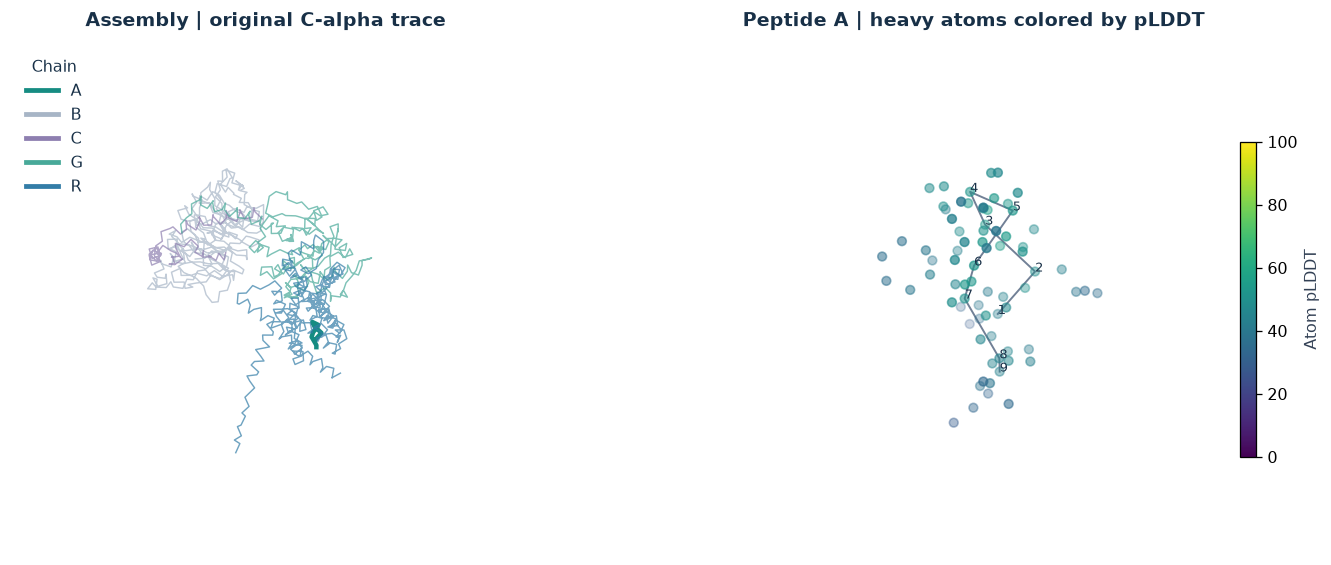

In [9]:
selected = load_sample(BATCH, STATE, SEED, SAMPLE)
display(metric_table(selected))
show_figure(structure_figure(selected))


### 受体口袋与改造位点

绿色：环肽；蓝灰色：受体；**橙色：Phe6；紫色：Leu2**。


In [10]:
show_3d(selected, highlight_sites=True)


## 05 · 原始预测的置信度

**pLDDT**：局部置信度，取值 0–100。**PAE**：相对位置的预测误差，单位 Å。pTM / ipTM 分别反映整体结构与界面置信度。

整体 PAE 图以行为参照、列为被评估 token；A–R 局部图以受体为横轴。


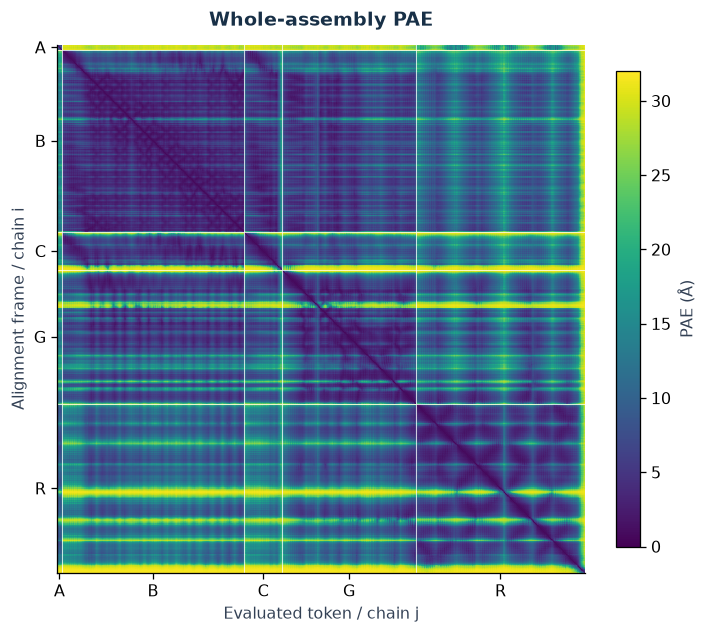

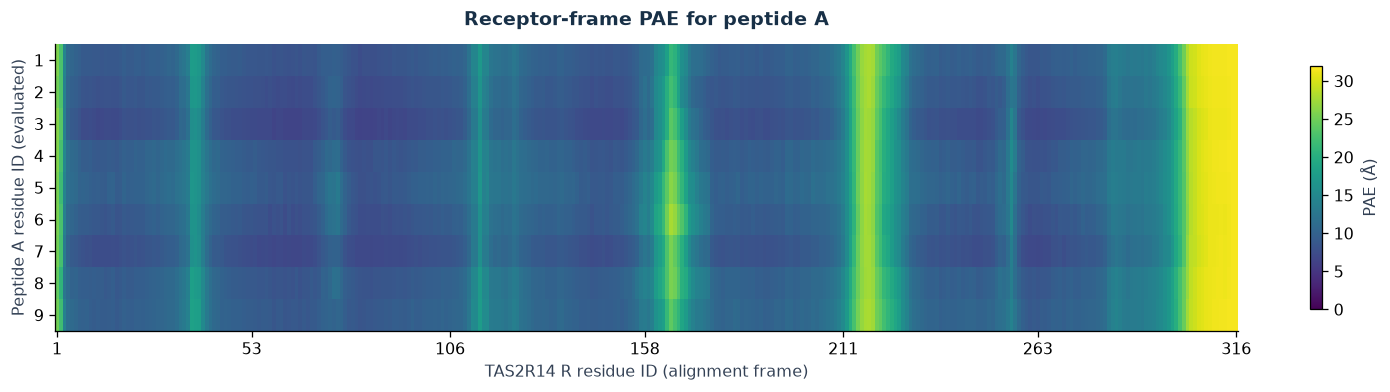

In [11]:
show_figure(confidence_figure(selected))
show_figure(interface_figure(selected))


### CLB 的 15 个原始样本

3 个 seed × 5 个 diffusion 样本。加粗单元格对应当前展示的 seed 1 / sample 0；`ranking_score` 为同一输入下的原生排序分数。


In [12]:
ranking_scores = {(int(row["seed"]), int(row["sample"])): float(row["ranking_score"])
                  for row in selected["ranking"]}
seeds = sorted({seed for seed, sample in ranking_scores})
samples = sorted({sample for seed, sample in ranking_scores})
rows = [[f"seed {seed}", *(f"{ranking_scores[(seed, sample)]:.6f}" if (seed, sample) in ranking_scores else "—"
                          for sample in samples)] for seed in seeds]
emphasize = [(i, j + 1) for i, seed in enumerate(seeds) for j, sample in enumerate(samples)
             if (seed, sample) == (SEED, SAMPLE)]
display(table(["Seed / Sample", *(f"sample {sample}" for sample in samples)], rows, emphasize=emphasize))


Seed / Sample,sample 0,sample 1,sample 2,sample 3,sample 4
seed 1,0.851329,0.853514,0.859128,0.854895,0.849467
seed 2,0.835690,0.842716,0.833959,0.840512,0.842409
seed 3,0.843470,0.844855,0.843250,0.841174,0.837931


## 06 · Phe6→Tyr 定点改造

第 6 位 Phe 替换为 Tyr，在芳香侧链对位引入羟基，保留九肽环状骨架。

*方案示意 · 模拟评分*

### 残基对照


In [13]:
f6y = next(case for case in DEMO_CASES["cases"] if case["key"] == "f6y")
show_design_summary(f6y)


序列 / 位点,1,2,3,4,5,6,7,8,9
改造前,Met,Leu,Ile,Pro,Pro,Phe,Phe,Val,Ile
改造后,Met,Leu,Ile,Pro,Pro,Tyr,Phe,Val,Ile


**模拟评分（0–100）**：CLB **72** → CLB-F6Y **82**（+10）。

### Phe6 与 Tyr6 的位点对照


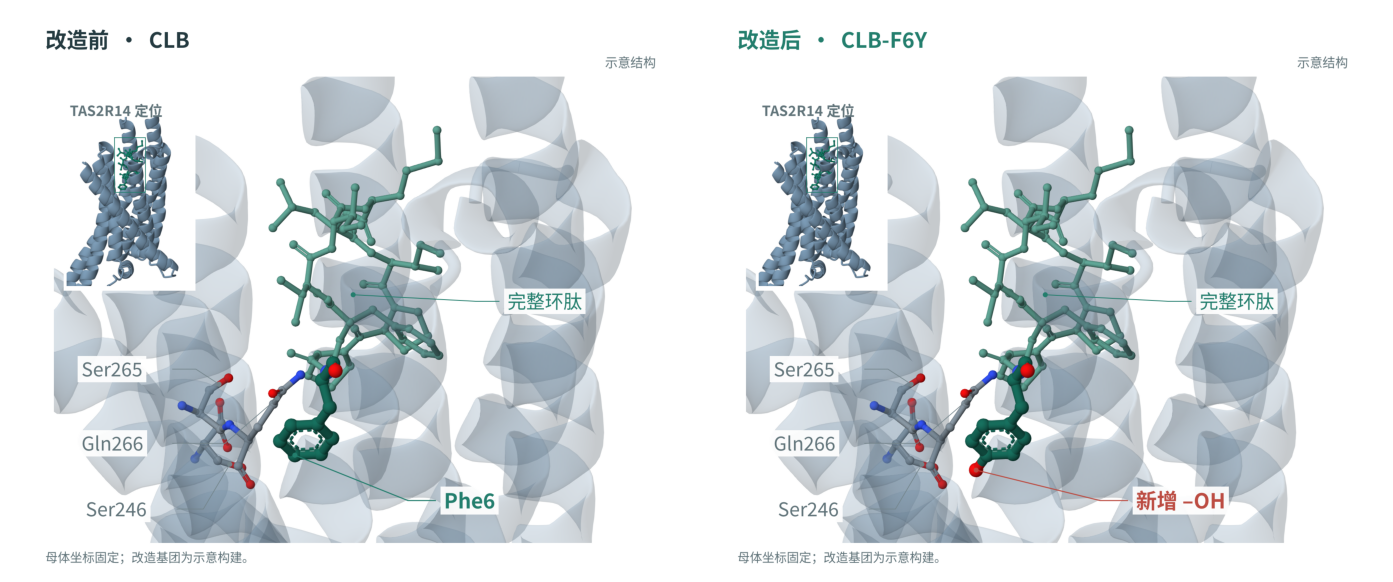

In [14]:
show_figure(design_site_figure(f6y))


## 07 · Leu2 主链 N-甲基化

在 CLB-F6Y 基础上，将 Leu2 的**主链酰胺 N–H 改为 N–CH₃**，第 6 位 Tyr 保留。

*方案示意 · 模拟评分*

### 残基对照


In [15]:
nme = next(case for case in DEMO_CASES["cases"] if case["key"] == "nme")
show_design_summary(nme)


序列 / 位点,1,2,3,4,5,6,7,8,9
改造前,Met,Leu,Ile,Pro,Pro,Tyr,Phe,Val,Ile
改造后,Met,NMe-Leu,Ile,Pro,Pro,Tyr,Phe,Val,Ile


**模拟评分（0–100）**：CLB-F6Y **82** → CLB-F6Y-NMeL2 **88**（+6）。

### Leu2 主链修饰的位点对照

橙色标出新增的 N-甲基。


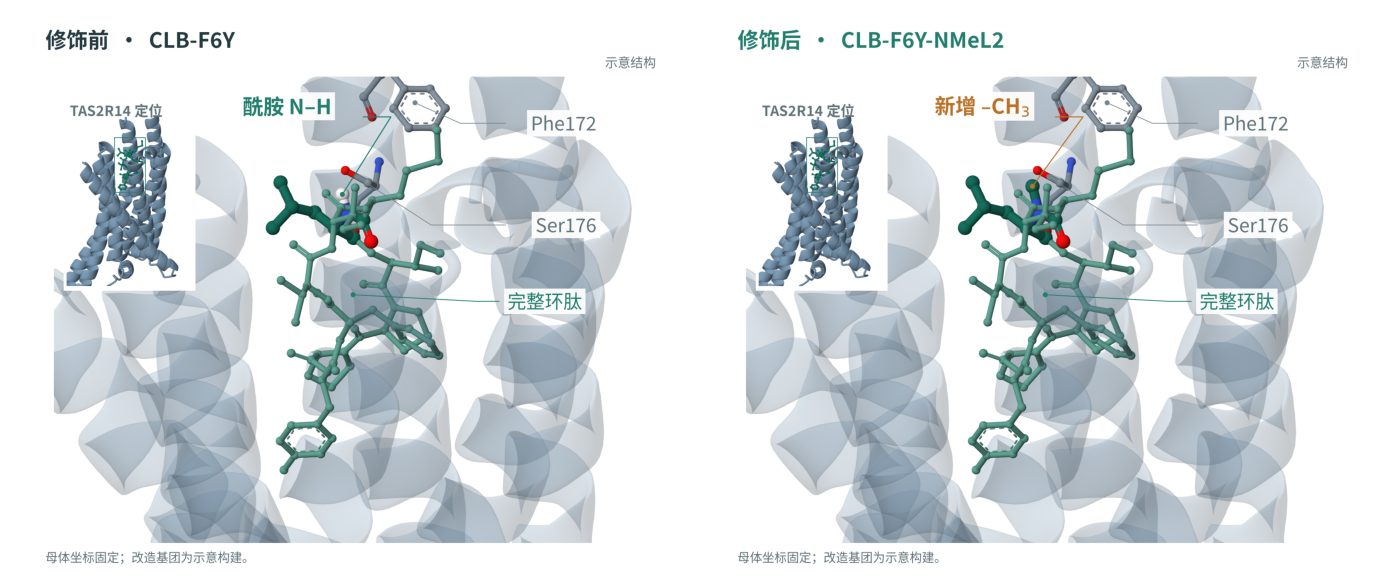

In [16]:
show_figure(design_site_figure(nme))


## 08 · HighFold3 预测结构库

四个批次，共 535 个原始预测样本。


In [17]:
try:
    import ipywidgets as widgets
except ImportError:
    display(Markdown("安装 `ipywidgets` 可使用菜单；上方默认样本与案例可继续查看。"))
else:
    cases = sorted({(key[0], key[1]) for key in SAMPLE_INDEX},
                   key=lambda item: (list(BATCH_LABELS).index(item[0]), item[1]))
    case_menu = widgets.Dropdown(options=[(f"{BATCH_LABELS[batch]} · {state.upper()}", (batch, state)) for batch, state in cases],
                                 value=(BATCH, STATE.lower()), description="批次 / 状态", layout=widgets.Layout(width="470px"), style={"description_width": "90px"})
    seed_menu = widgets.Dropdown(description="Seed", layout=widgets.Layout(width="190px"))
    sample_menu = widgets.Dropdown(description="Sample", layout=widgets.Layout(width="190px"))
    enable_3d = widgets.Checkbox(value=False, description="显示交互三维视图", indent=False)
    render_button = widgets.Button(description="展示样本", button_style="info", icon="play")
    browser_output = widgets.Output()
    synchronizing = False

    def synchronize(change=None):
        global synchronizing
        if synchronizing:
            return
        synchronizing = True
        try:
            batch, state = case_menu.value
            available = [key for key in SAMPLE_INDEX if key[:2] == (batch, state)]
            old_seed = seed_menu.value
            seed_menu.options = sorted({key[2] for key in available})
            if old_seed in seed_menu.options:
                seed_menu.value = old_seed
            old_sample = sample_menu.value
            sample_menu.options = sorted({key[3] for key in available if key[2] == seed_menu.value})
            if old_sample in sample_menu.options:
                sample_menu.value = old_sample
        finally:
            synchronizing = False

    def render_case(button=None):
        with browser_output:
            browser_output.clear_output(wait=True)
            batch, state = case_menu.value
            current = load_sample(batch, state, seed_menu.value, sample_menu.value)
            display(Markdown(f"### {state.upper()} · {BATCH_LABELS[batch]} · seed {seed_menu.value} / sample {sample_menu.value}"))
            display(metric_table(current))
            show_figure(structure_figure(current))
            show_figure(confidence_figure(current))
            show_figure(interface_figure(current))
            if enable_3d.value:
                show_3d(current)

    case_menu.observe(synchronize, names="value")
    seed_menu.observe(synchronize, names="value")
    render_button.on_click(render_case)
    synchronize()
    seed_menu.value, sample_menu.value = SEED, SAMPLE
    display(widgets.VBox([case_menu, widgets.HBox([seed_menu, sample_menu]),
                          widgets.HBox([render_button, enable_3d]), browser_output]))
